# CAD export of lens systems

A lens design ends as a prescription: radii, thicknesses, glasses, aspheric
coefficients and clear apertures. The mechanical designer needs solids:
lenses with a rim that is larger than the clear aperture so that a mount
can hold them, surfaces that go on to that rim in a way the optical shop
can polish, protective bevels on the edges,
and the ray bundle to check that the barrel, the spacers and the stop do
not clip the light. This notebook turns `raytrace.System` objects into such
a model with `pyoptics.cad` and writes it to STEP, the exchange format every
CAD system reads.

`pyoptics.cad` builds on [build123d](https://github.com/gumyr/build123d),
a Python front end to the OpenCascade kernel (``pip install pyoptics[cad]``).
The model is a boundary representation: spheres and planes are exact
surfaces in the STEP file, aspheres, toroids and freeforms are B-splines
fitted to the sag within a set tolerance.

1. A cemented achromat: lens solids, rims and bevels, the STEP file
2. What happens between clear aperture and rim
3. A Cooke triplet in a barrel with retaining rings, spacers and a stop
4. Freeforms, tilted elements and a fold mirror
5. A Fresnel lens
6. A lithography lens with 21 elements in 3D
7. Toric and cylindrical lenses

In [1]:
import io
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import cad
from pyoptics.fresnel import FresnelSurface
from IPython.display import Image, display

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
OUT = tempfile.mkdtemp()
t_start = time.time()

## 1. A cemented achromat

A 100 mm achromat of the common 1 inch size: a biconvex crown lens
(n = 1.5168) cemented to a meniscus of dense flint (n = 1.6727), clear
aperture 23 mm, rim diameter 25.4 mm. `System.elements()` sees the
cemented pair as one element; in CAD it becomes two solids, `L1a` and
`L1b`, that touch along the cemented surface.

`Mechanics` holds the mechanical data of an element: here a rim 1.2 mm
outside the clear aperture and 0.3 mm bevels. Between the clear aperture
and the rim the spheres simply go on (the default, see section 2): a lens
is polished as a whole, so the surface that the shop makes runs out to
the bevel.
The bevels only go on edges that face air; a bevel on the cemented
interface would leave a groove for the cement.

efl 100.13 mm, elements [(1, 3)]


built in 1.43 s
L1a:  1243.4 mm³, valid True, faces ['CONE', 'CYLINDER', 'SPHERE']
L1b:  1556.9 mm³, valid True, faces ['CONE', 'CYLINDER', 'SPHERE']


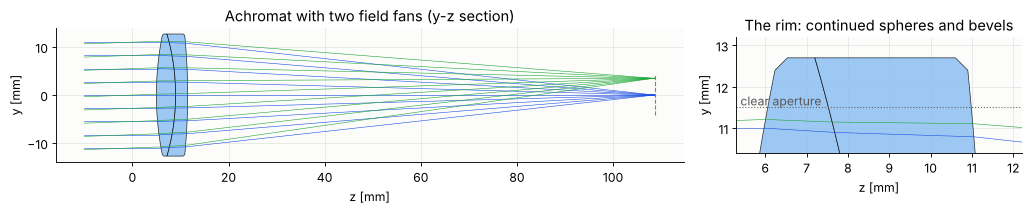

In [2]:
achromat = rt.System([rt.Surface(np.inf, 5.0, semi_diameter=11.0),
                      rt.Surface(62.8, 4.0, n_after=1.5168, semi_diameter=11.5),
                      rt.Surface(-45.7, 2.5, n_after=1.6727, semi_diameter=11.5),
                      rt.Surface(-128.2, 95.0, n_after=1.0, semi_diameter=11.5)],
                     0, 550e-6, field_angle=np.radians(2.0)).at_paraxial_focus()
print("efl {:.2f} mm, elements {}".format(achromat.paraxial().efl, achromat.elements()))

t = time.time()
model = cad.system_model(achromat, n_rays=9, ray_start=10.0,
                         mechanics=cad.Mechanics(margin=1.2, bevel=0.3))
print("built in {:.2f} s".format(time.time() - t))
for lens in model.lenses:
    kinds = sorted({f.geom_type.name for f in lens.faces()})
    print("{}: {:7.1f} mm³, valid {}, faces {}".format(lens.label, lens.volume, lens.is_valid, kinds))

fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.2, 1]})
cad.plot_section(model, axs[0])
axs[0].set_title("Achromat with two field fans (y-z section)")
cad.plot_section(model, axs[1])
axs[1].set_xlim(5.3, 12.2)
axs[1].set_ylim(10.4, 13.2)
axs[1].axhline(11.5, color="0.4", ls=":", lw=1)
axs[1].text(5.4, 11.55, "clear aperture", color="0.35")
axs[1].set_title("The rim: continued spheres and bevels")
fig.tight_layout()

The optical faces are `SPHERE` surfaces, the rim a `CYLINDER` and the
bevels `CONE`s: nothing is tessellated, so the CAD system measures the
same radii as the prescription. The solid of the crown lens can be checked
against an integral over its section: the volume between the two spheres
out to the rim, minus the ring that the front bevel cuts off between its
45° cone and the sphere.

In [3]:
def sag(R, r):
    return R - np.sign(R)*np.sqrt(R**2 - r**2)

rc, rm, b = 11.5, 12.7, 0.3
r = np.linspace(0, rm, 20001)
thick = 4.0 + sag(-45.7, r) - sag(62.8, r)
z_b = sag(62.8, rm - b)          # the front sphere ends at rm - b, the cone runs to the rim
cut = np.clip(z_b + (r - (rm - b)) - sag(62.8, r), 0, None)*(r >= rm - b)
V = np.trapezoid(2*np.pi*r*(thick - cut), r)
print("L1a: CAD {:.4f} mm³, integral {:.4f} mm³".format(model.lenses[0].volume, V))

L1a: CAD 1243.3815 mm³, integral 1243.3815 mm³


`export_step()` writes the model as one assembly: `lenses`, `rays` (one
polyline per ray, coloured by field) and the image plane, all in
millimetres whatever the units of the system. With `rays="tube"` the rays
become thin cylinders instead, which show up in renderings and can take
part in interference checks; `pupil` picks the rays (a meridional fan
`"y"`, `"x"`, both, a `"ring"` at the rim of the pupil or explicit
coordinates).

In [4]:
path = os.path.join(OUT, "achromat.step")
cad.export_step(model, path)
tubes = cad.system_model(achromat, n_rays=12, pupil="ring", rays="tube", ray_radius=0.05,
                         mechanics=cad.Mechanics(margin=1.2, bevel=0.3))
path_tubes = os.path.join(OUT, "achromat_tubes.step")
cad.export_step(tubes, path_tubes)
for p in (path, path_tubes):
    print("{}: {:.0f} kB".format(os.path.basename(p), os.path.getsize(p)/1e3))

achromat.step: 123 kB
achromat_tubes.step: 1140 kB


## 2. Between clear aperture and rim

The clear aperture is what the optics needs; the rim is what the mount
needs. `Mechanics` sets the rim semi-diameter directly (`semi_diameter`) or
as a `margin` over the largest clear semi-diameter of the element, and
`land` decides what fills the annulus between them:

- `"continue"` (the default): the surface goes on in a way that is
  polished together with the optical surface. A sphere stays the same
  sphere, a toroid the same toroid (section 7), and an asphere goes on as
  its **best fit sphere**, the sphere through the vertex and the rim of the
  clear aperture, where it joins the asphere. A flat annulus next to a
  curved surface cannot be polished in the same run, and an asphere would
  only make the outer zone harder to polish for nothing. Only Fresnel
  surfaces (molded) and a sphere that is smaller than the rim (a steep
  face with a small clear aperture on a large element) get a flat land.
- `"flat"`: a plane perpendicular to the axis at the height of the clear
  aperture rim, a seat for a retaining ring or a spacer on molded or
  diamond turned parts.
- `"extend"`: the optical surface itself, aspheres included, up to the
  rim.

The edges at the rim are the ones that chip, so the bevels go there. A
lens whose surfaces would cross before the rim (a strong biconvex lens
with a large margin) cannot be built; `system_model()` refuses it with the
edge thickness that it found. With flat lands the same lens can have a
rim of any size.

land = 'continue' with a 4 mm margin: Edge thickness -1.93 below 0.1 at semi-diameter 13.0
land = 'flat' with a 4 mm margin: fine


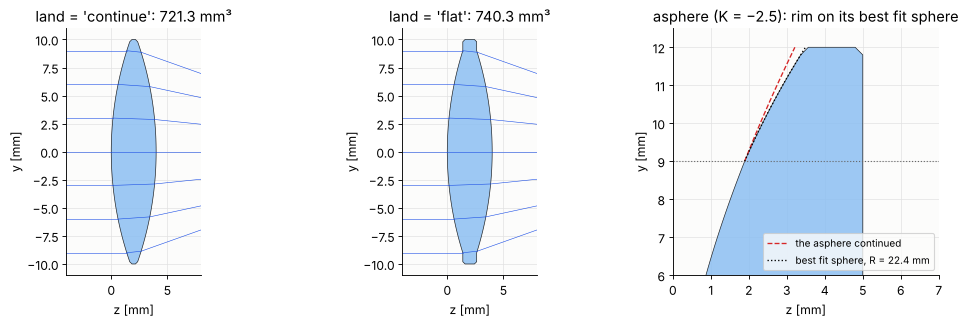

In [5]:
lens = rt.System([rt.Surface(30.0, 4.0, n_after=1.5168, semi_diameter=9.0),
                  rt.Surface(-30.0, 40.0, n_after=1.0, semi_diameter=9.0)], 0, 550e-6)
asphere = rt.Surface(20.0, 5.0, n_after=1.5168, conic=-2.5, semi_diameter=9.0)
asph = rt.System([asphere, rt.Surface(np.inf, 40.0, n_after=1.0, semi_diameter=9.0)], 0, 550e-6)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, land in zip(axs[:2], ["continue", "flat"]):
    m = cad.system_model(lens, n_rays=7, ray_start=4, image_plane=False,
                         mechanics=cad.Mechanics(margin=1.0, land=land, bevel=0.2))
    cad.plot_section(m, ax)
    ax.set_xlim(-4, 8)
    ax.set_ylim(-11, 11)
    ax.set_title("land = {!r}: {:.1f} mm³".format(land, m.lenses[0].volume))
for land in ("continue", "flat"):
    try:
        cad.system_model(lens, rays=None, mechanics=cad.Mechanics(margin=4.0, land=land))
        print("land = {!r} with a 4 mm margin: fine".format(land))
    except ValueError as err:
        print("land = {!r} with a 4 mm margin:".format(land), str(err).split(" between")[0])
m = cad.system_model(asph, n_rays=7, ray_start=4, image_plane=False,
                     mechanics=cad.Mechanics(margin=3.0, bevel=0.2))
cad.plot_section(m, axs[2], rays=False)
r = np.linspace(9.0, 12.0, 100)
z9 = asphere.sag(np.array([81.0]))[0]
R_bfs = (81 + z9**2)/(2*z9)
axs[2].plot(asphere.sag(r**2), r, color="C3", ls="--", lw=1.2, label="the asphere continued")
axs[2].plot(R_bfs - np.sqrt(R_bfs**2 - r**2), r, color="k", ls=":", lw=1.2,
            label="best fit sphere, R = {:.1f} mm".format(R_bfs))
axs[2].axhline(9.0, color="0.4", ls=":", lw=1)
axs[2].set_xlim(0, 7)
axs[2].set_ylim(6, 12.5)
axs[2].legend(loc="lower right", fontsize=9)
axs[2].set_title("asphere (K = −2.5): rim on its best fit sphere")
fig.tight_layout()

## 3. A Cooke triplet in a barrel

With `mount=cad.Mount()` the model gets a first cut of the mechanics of a
coaxial lens: a barrel whose bore is the largest rim plus a radial
clearance, a retaining ring in front of the first and behind the last
element, spacers between the elements and an aperture plate at a stop that
lies in air. The rings and spacers are built as solids of revolution and
then cut by the lens solids, so they sit exactly on the rims and bevels.
Their bore starts a little outside the clear aperture of the lens they
touch (`spacer_clearance`) and runs conically from one lens to the next:
the edge of a bundle of straight rays between two surfaces is a convex
function of z and stays inside that cone.

The triplet is the classic f/4.5 Cooke design (efl about 47 mm, ±10°),
whose stop sits in the air space between the negative lens and the rear
crown. Its positive lenses are thin at the edge already: with continued
spheres a rim 1 mm outside the clear aperture is about what they allow.

built in 0.53 s
part        volume [mm³]
L1              213.8
L2              197.9
L3              203.3
barrel         2176.8
ring_front      110.3
spacer_1        435.8
spacer_2a       194.5
spacer_2b       359.0
ring_back       265.5
stop             37.1


largest overlap of mount and lenses: 0.0e+00 mm³
closest approach of a ring or spacer to a traced ray: 0.66 mm


True

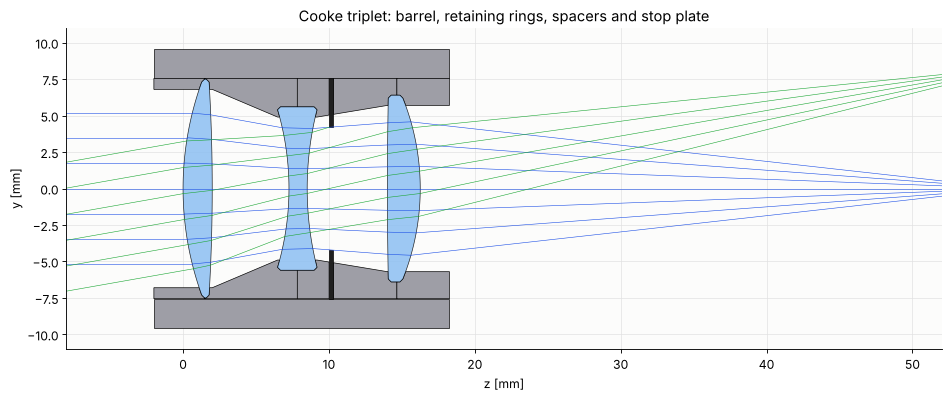

In [6]:
triplet = rt.System([rt.Surface(21.48, 2.0, n_after=1.6204, semi_diameter=6.5),
                     rt.Surface(-124.1, 5.26, n_after=1.0, semi_diameter=6.5),
                     rt.Surface(-19.1, 1.25, n_after=1.6034, semi_diameter=4.6),
                     rt.Surface(22.0, 1.5, n_after=1.0, semi_diameter=4.6),
                     rt.Surface(np.inf, 4.0, semi_diameter=4.2),
                     rt.Surface(328.9, 2.25, n_after=1.6204, semi_diameter=5.4),
                     rt.Surface(-16.7, 43.0, n_after=1.0, semi_diameter=5.4)],
                    4, 550e-6, field_angle=np.radians(10)).at_paraxial_focus()
t = time.time()
cooke = cad.system_model(triplet, n_rays=7, ray_start=8, mechanics=cad.Mechanics(margin=1.0, bevel=0.2),
                         mount=cad.Mount(wall=2.0, ring_length=2.0, spacer_clearance=0.3))
print("built in {:.2f} s".format(time.time() - t))
print("part        volume [mm³]")
for part in cooke.lenses + cooke.mount:
    print("{:10s} {:10.1f}".format(part.label, part.volume))

clash = max((p & l).volume if (p & l) is not None else 0.0 for p in cooke.mount for l in cooke.lenses)
gap = min(p.distance_to(r) for p in cooke.mount if p.label not in ("barrel", "stop") for r in cooke.rays)
print("largest overlap of mount and lenses: {:.1e} mm³".format(clash))
print("closest approach of a ring or spacer to a traced ray: {:.2f} mm".format(gap))

fig, ax = plt.subplots(figsize=(12, 5))
cad.plot_section(cooke, ax)
ax.set_xlim(-8, 52)
ax.set_title("Cooke triplet: barrel, retaining rings, spacers and stop plate")
fig.tight_layout()
cad.export_step(cooke, os.path.join(OUT, "cooke_triplet.step"))

The negative lens has the smallest rim, so it sits in the bore with a
radial gap; the spacers on both sides reach around its rim and centre it.
In a real barrel the bore would step down to each lens with a fit, and the
retaining rings would be threaded; the generated parts are a starting
point that already has the right axial positions and contact faces.

## 4. Freeforms, tilted elements and a fold mirror

Not every slab is a solid of revolution. Surfaces with a `sag_xy(x, y)`
(`ZernikeSurface`, `qaspheres.Q2DSurface`, `freeform.TabulatedSurface`) and
slabs whose surfaces are tilted or decentred against each other are cut
from a cylinder along the axis of their first surface: by a B-spline face
through the sag on a grid, or by the revolved section of a rotationally
symmetric surface. Rims and bevels work as before: a freeform goes on as
itself up to the rim. With `land="flat"` the rim height of a freeform
changes around the circumference, so the flat land is put at the point of
the rim that lies farthest towards air, and a short step joins it to the
optical face.

The example has a plate with a Zernike astigmatism and trefoil departure,
a window tilted by 8° and a fold mirror with a freeform figure on a
coordinate break of 45°. The mirror gets a substrate with a flat back
`mirror_thickness` behind its face.

built in 0.55 s
L1:   845.3 mm³, faces ['BSPLINE', 'CONE', 'CYLINDER', 'PLANE']
L2:   396.2 mm³, faces ['CONE', 'CYLINDER', 'PLANE']
M3:  1258.7 mm³, faces ['BSPLINE', 'CYLINDER', 'PLANE']


True

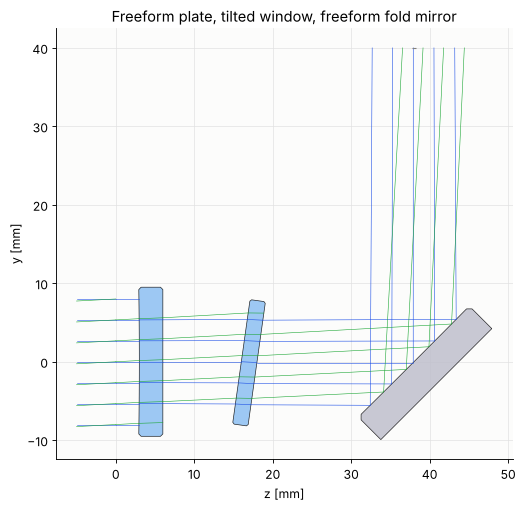

In [7]:
fold = rt.System([rt.Surface(np.inf, 3.0, semi_diameter=8.0),
                  rt.ZernikeSurface(np.inf, 3.0, zernike={5: 0.05, 10: 0.03}, norm_radius=8.0,
                                    n_after=1.5168, semi_diameter=8.0),
                  rt.Surface(np.inf, 10.0, n_after=1.0, semi_diameter=8.0),
                  rt.Surface(np.inf, 2.0, n_after=1.5168, semi_diameter=7.0, tilt=(np.radians(8), 0, 0)),
                  rt.Surface(np.inf, 20.0, n_after=1.0, semi_diameter=7.0, tilt=(np.radians(8), 0, 0)),
                  rt.CoordinateBreak(tilt=(np.pi/4, 0, 0)),
                  rt.ZernikeSurface(np.inf, 0.0, zernike={5: 0.02}, norm_radius=8.0, mirror=True,
                                    semi_diameter=8.0),
                  rt.CoordinateBreak(tilt=(np.pi/4, 0, 0), thickness=-40.0)],
                 0, 550e-6, field_angle=np.radians(3.0))
t = time.time()
folded = cad.system_model(fold, n_rays=7, ray_start=5,
                          mechanics={0: cad.Mechanics(margin=1.5, bevel=0.3),
                                     1: cad.Mechanics(margin=1.0, bevel=0.2),
                                     2: cad.Mechanics(margin=2.0, mirror_thickness=4.0, bevel=0.5)})
print("built in {:.2f} s".format(time.time() - t))
for part in folded.lenses:
    print("{}: {:7.1f} mm³, faces {}".format(part.label, part.volume,
                                            sorted({f.geom_type.name for f in part.faces()})))
fig, ax = plt.subplots(figsize=(8, 6.5))
cad.plot_section(folded, ax)
ax.set_title("Freeform plate, tilted window, freeform fold mirror")
fig.tight_layout()
cad.export_step(folded, os.path.join(OUT, "fold.step"))

The trefoil term of the plate bends the rays out of the meridional plane,
so the section shows their projection. The Zernike terms average to zero
over every circle, so the plate, continued to its rim, has the volume of a
3 mm disk of radius 9.5 mm minus what the bevels remove; the tests of
`pyoptics.cad` check this and the flat lands against integrals over the
sag.

## 5. A Fresnel lens

A `fresnel.FresnelSurface` (notebook [51 (Fresnel lenses)](51_fresnel_lenses.ipynb))
has a stepped section: facets that follow the parent surface and risers
between them. The CAD section uses its `section()` with a B-spline per
facet and straight risers, so the facets keep their curvature and the
risers their draft angle. A Fresnel lens is molded, not
polished: its rim is a flat land at the height of the last facet.

24 faces, 699.5 mm³


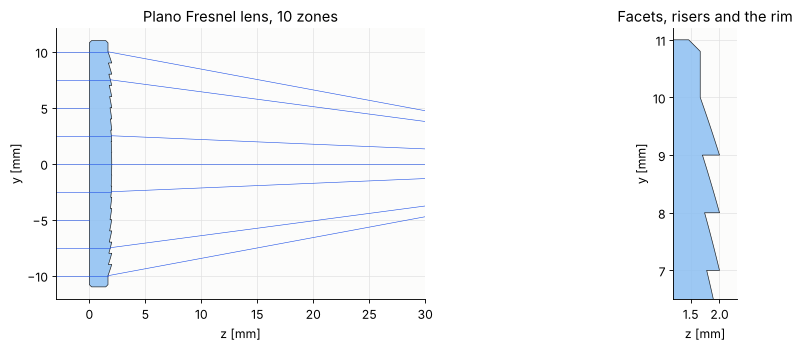

In [8]:
fresnel = FresnelSurface(-30.0, n_zones=10, radius=10.0, n_after=1.0, semi_diameter=10.0,
                         thickness=60.0)
fl = rt.System([rt.Surface(np.inf, 2.0, n_after=1.5, semi_diameter=10.0), fresnel], 0, 550e-6)
fm = cad.system_model(fl, n_rays=9, ray_start=3, image_plane=False,
                      mechanics=cad.Mechanics(margin=1.0, bevel=0.2))
print("{} faces, {:.1f} mm³".format(len(fm.lenses[0].faces()), fm.lenses[0].volume))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1]})
cad.plot_section(fm, axs[0])
axs[0].set_xlim(-3, 30)
axs[0].set_title("Plano Fresnel lens, 10 zones")
cad.plot_section(fm, axs[1], rays=False)
axs[1].set_xlim(1.2, 2.3)
axs[1].set_ylim(6.5, 11.2)
axs[1].set_title("Facets, risers and the rim")
fig.tight_layout()

## 6. A lithography lens with 21 elements in 3D

The all fused silica KrF projection lens by J. B. Caldwell
(`raytrace.caldwell_krf_lens()`, the lens of notebook
[44 (Seidel aberrations)](44_seidel_caldwell_lens.ipynb)) images a
reticle 4× reduced at NA 0.56 over 1 m from object to image. Each of its
21 singlets gets a rim 3 mm outside its clear aperture and 0.5 mm bevels,
with every surface continued to the rim, except the steep concave back of
the thick meniscus in front of the last two lenses (R = 75.7 mm on a rim
of 82.3 mm), which gets a flat land; the rays leave the reticle at the axis, 70 % and the full
field. The section shows the rims and bevels of all lenses at once,
`plot_3d()` the tessellated solids as build123d hands them to the STEP and
glTF writers.

21 lenses built in 0.4 s
fused silica: 10732 cm³, 23.6 kg


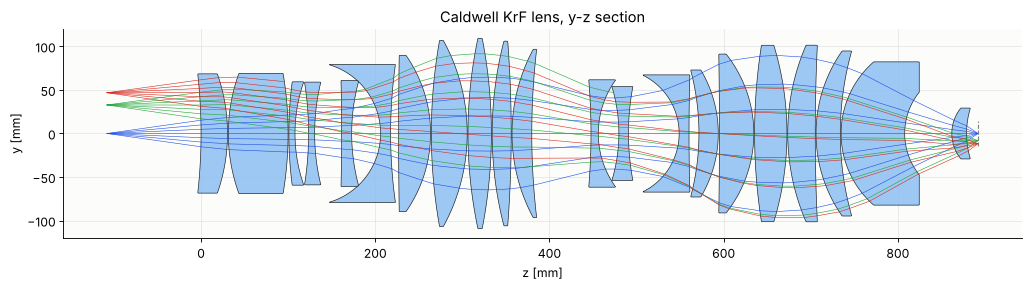

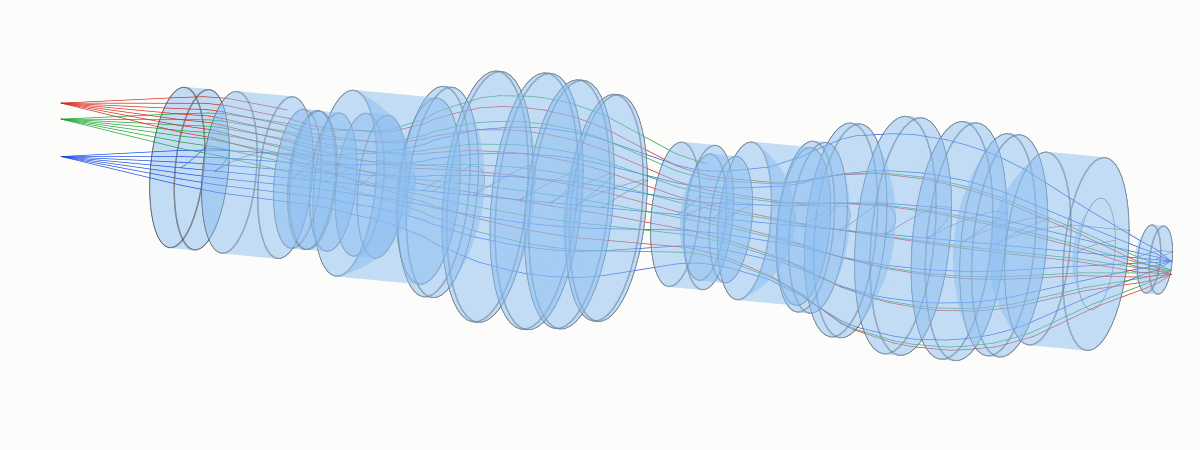

caldwell.step: 771 kB
caldwell.glb: 648 kB


In [9]:
caldwell = rt.caldwell_krf_lens()
t = time.time()
litho = cad.system_model(caldwell, fields=[0.0, 0.7*caldwell.max_field, caldwell.max_field],
                         n_rays=7, ray_start=0, mechanics=cad.Mechanics(margin=3.0, bevel=0.5))
print("{} lenses built in {:.1f} s".format(len(litho.lenses), time.time() - t))
glass = sum(lens.volume for lens in litho.lenses)
print("fused silica: {:.0f} cm³, {:.1f} kg".format(glass/1e3, 2.201e-6*glass))

fig, ax = plt.subplots(figsize=(13, 4.2))
cad.plot_section(litho, ax)
ax.set_title("Caldwell KrF lens, y-z section")
fig.tight_layout()
plt.show()

# matplotlib fits the 3D box into a square: a square axes as wide as the
# figure, of which the figure shows the middle band
fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_axes([0, 0.5 - 12/4.5/2, 1, 12/4.5], projection="3d")
cad.plot_3d(litho, ax, elev=15, azim=-70)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)  # without the inline backend's tight box
plt.close(fig)
display(Image(buf.getvalue()))

for name, writer in [("caldwell.step", cad.export_step), ("caldwell.glb", cad.export_gltf)]:
    path = os.path.join(OUT, name)
    writer(litho, path)
    print("{}: {:.0f} kB".format(name, os.path.getsize(path)/1e3))

The glTF file (`export_gltf()`) is what web viewers and three.js load; it
holds the tessellated lenses with their names and colours, the STEP file
the exact geometry for the CAD system.

## 7. Toric and cylindrical lenses

`raytrace.ToroidalSurface` (a curve in the y-z plane rotated about an axis
parallel to y, so that the x-z section is a circle of radius R_x) and
`raytrace.BiconicSurface` (conic sections of different curvature in x and
y) are surfaces with a `sag_xy`, cut from the cylinder of the rim by a
B-spline face. With `land="continue"` the torus goes on as the same torus
to the rim: a toric surface is generated and polished as a whole on a
toric lap, like a sphere on a spherical one.

The first lens is the toric spectacle lens that notebook
[129 (progressive spectacle lenses)](129_progressive_lenses.ipynb) optimizes for an
astigmatic eye: a +4 D spherical front, a toric back with R = 77.58 mm and
R_x = 112.20 mm rotated by 20° about the axis (a cylinder of −1.98 D at
20°), 2 mm centre thickness, here as an uncut round blank of 52 mm
before it is edged to the frame. The second is a plano-convex cylinder
lens with f = 50 mm in y and no power in x (R_x = ∞), which turns a
parallel beam into a line focus along x.

built in 0.47 s
spectacle lens: 5297.1 mm³, valid True, faces ['BSPLINE', 'CYLINDER', 'SPHERE']
cylinder lens: 1290.0 mm³, valid True, faces ['BSPLINE', 'CONE', 'CYLINDER', 'PLANE']
edge thickness of the blank: 3.74 mm at 110°, 2.31 mm at 20°
volume: CAD 5297.1 mm³, integral 5296.6 mm³


largest distance of the torus from the CAD face: 0.63 nm


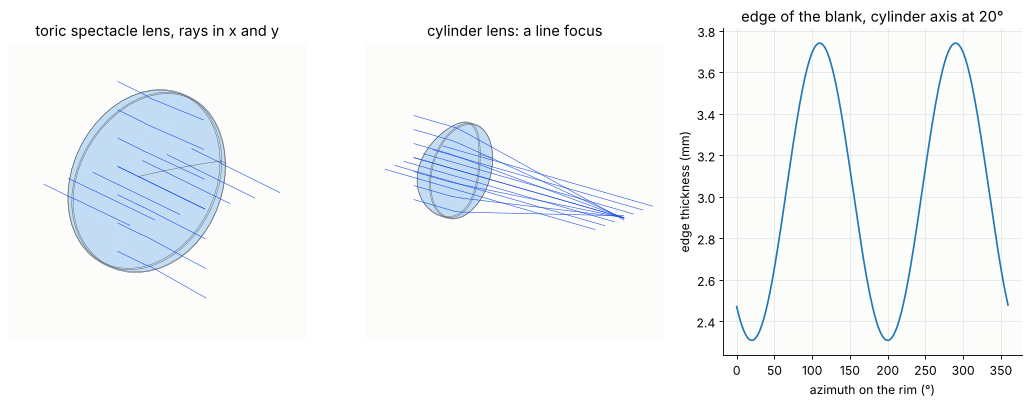

In [10]:
# the toric spectacle lens of notebook 129 (progressive spectacle lenses), section 8, as an uncut blank
toric_back = rt.ToroidalSurface(77.58, 30.0, R_x=112.20, n_after=1.0, semi_diameter=25.0,
                                tilt=(0.0, 0.0, np.radians(20.0)))
spectacle = rt.System([rt.Surface(124.5, 2.0, n_after=1.498, semi_diameter=25.0), toric_back],
                      0, 555e-6)
# a plano-convex cylinder lens, f = 50 mm in y, no power in x
cylinder = rt.System([rt.ToroidalSurface(25.84, 4.0, R_x=np.inf, n_after=1.5168,
                                         semi_diameter=10.0),
                      rt.Surface(np.inf, 47.4, n_after=1.0, semi_diameter=10.0)], 0, 550e-6)
t = time.time()
spec = cad.system_model(spectacle, n_rays=7, pupil="xy", ray_start=10.0, image_plane=False,
                        mechanics=cad.Mechanics(margin=1.0, bevel=0.3))
cyl = cad.system_model(cylinder, n_rays=7, pupil="xy", ray_start=10.0,
                       mechanics=cad.Mechanics(margin=1.0, bevel=0.2))
print("built in {:.2f} s".format(time.time() - t))
for name, m in (("spectacle lens", spec), ("cylinder lens", cyl)):
    lens = m.lenses[0]
    print("{}: {:.1f} mm³, valid {}, faces {}".format(name, lens.volume, lens.is_valid,
                                                     sorted({f.geom_type.name for f in lens.faces()})))

# edge thickness around the rim and the volume from the sag (without the bevels)
phi = np.linspace(0, 2*np.pi, 721)[:-1]            # azimuth in the lens
loc = phi - toric_back.tilt[2]                       # in the frame of the torus
rm, b = 26.0, 0.3
edge = 2.0 + toric_back.sag_xy(rm*np.cos(loc), rm*np.sin(loc)) - spectacle.surfaces[0].sag(rm**2)
print("edge thickness of the blank: {:.2f} mm at {:.0f}°, {:.2f} mm at {:.0f}°".format(
    edge.max(), np.degrees(phi[edge.argmax()]) % 180, edge.min(), np.degrees(phi[edge.argmin()]) % 180))
r = np.linspace(0, rm, 1301)
Rg, Pg = np.meshgrid(r, phi)
thick = 2.0 + toric_back.sag_xy(Rg*np.cos(Pg), Rg*np.sin(Pg)) - spectacle.surfaces[0].sag(Rg**2)
V = np.trapezoid(np.mean(thick, axis=0)*2*np.pi*r, r) - 2*2*np.pi*(rm - b/3)*b**2/2
print("volume: CAD {:.1f} mm³, integral {:.1f} mm³".format(spec.lenses[0].volume, V))
import build123d as bd
x, y = np.meshgrid(np.linspace(-25, 25, 21), np.linspace(-25, 25, 21))
inside = np.hypot(x, y) < 25.5                   # inside the bevel
o, R = spectacle.frames()[0][1]
face = max((f for f in spec.lenses[0].faces() if f.geom_type.name == "BSPLINE"),
           key=lambda f: f.area)                    # the toric face
dev = [face.distance_to(bd.Vector(*(o + R @ [xx, yy, toric_back.sag_xy(xx, yy)])))
       for xx, yy in zip(x[inside], y[inside])]
print("largest distance of the torus from the CAD face: {:.2g} nm".format(1e6*max(dev)))

fig = plt.figure(figsize=(13, 5.2))
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
cad.plot_3d(spec, ax1, elev=20, azim=-35)
ax1.set_title("toric spectacle lens, rays in x and y")
ax2 = fig.add_subplot(1, 3, 2, projection="3d")
cad.plot_3d(cyl, ax2, elev=20, azim=-50)
ax2.set_title("cylinder lens: a line focus")
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(np.degrees(phi), edge, color="C0")
ax3.set_xlabel("azimuth on the rim (°)")
ax3.set_ylabel("edge thickness (mm)")
ax3.set_title("edge of the blank, cylinder axis at 20°")
fig.tight_layout()
for name, m in (("toric_spectacle_lens.step", spec), ("cylinder_lens.step", cyl)):
    cad.export_step(m, os.path.join(OUT, name))

The edge of the toric blank is thinnest in the meridian of the cylinder
axis (20°, the weaker back curvature) and thickest at right angles to it
(110°); a minus cylinder lens always has this edge with two thick and two
thin sides, and the frame shape decides how much of it is left after
edging. The B-spline face of the CAD solid follows the torus to about a
nanometre, and the volume agrees with the integral over the sag up to the
bevels.

## Summary

- `cad.system_model()` turns a `raytrace.System` into lens solids, mirror
  substrates, ray fans and the image plane; `cad.export_step()` writes them
  as one STEP assembly in millimetres with names and colours.
- Spheres and planes are exact surfaces, aspheres B-splines within
  `tolerance` (0.1 µm by default), toroids, biconics and freeforms
  B-spline faces.
- `Mechanics` per element sets the rim, what lies between the clear
  aperture and the rim (by default the surface continued as it is
  polished: spheres and toroids as themselves, aspheres as their best fit
  sphere; or flat lands, or the extended optical surface), bevels on edges
  in air, mirror substrates and the smallest edge thickness.
- `Mount` adds a barrel, retaining rings, spacers and a stop plate for
  coaxial lenses, cut to the lens solids and clear of the traced rays.
- `cad.plot_section()` draws a section of the model and `cad.plot_3d()` the
  tessellated solids, quick checks before the STEP file goes to the CAD
  system; `cad.export_gltf()` writes the tessellated model for web viewers.

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 14 s
